# <b> <span style="color:purple">Python DA Assignment 2 - Data Visualization </span> </b>

### <b> <span style="color:purple">1) Loading the Taxis Dataset </span> </b>

In [3]:
import seaborn as sns 
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = sns.load_dataset("taxis") 
df.head(10)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
5,2019-03-11 10:37:23,2019-03-11 10:47:31,1,0.49,7.5,2.16,0.0,12.96,yellow,credit card,Times Sq/Theatre District,Midtown East,Manhattan,Manhattan
6,2019-03-26 21:07:31,2019-03-26 21:17:29,1,3.65,13.0,2.00,0.0,18.80,yellow,credit card,Battery Park City,Two Bridges/Seward Park,Manhattan,Manhattan
7,2019-03-22 12:47:13,2019-03-22 12:58:17,0,1.40,8.5,0.00,0.0,11.80,yellow,NaN,Murray Hill,Flatiron,Manhattan,Manhattan
8,2019-03-23 11:48:50,2019-03-23 12:06:14,1,3.63,15.0,1.00,0.0,19.30,yellow,credit card,East Harlem South,Midtown Center,Manhattan,Manhattan
9,2019-03-08 16:18:37,2019-03-08 16:26:57,1,1.52,8.0,1.00,0.0,13.30,yellow,credit card,Lincoln Square East,Central Park,Manhattan,Manhattan


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


<span style="color:green"><b>Seaborn, Pandas, and Matplotlib libraries are imported for data loading, manipulation, and visualization.The taxis dataset is loaded into a DataFrame df. The df.head(10) displays the first 10 rows of the dataset, df.info() provides information about the columns, data types, and non-null values. This helps to understand the structure and contents of the dataset.</b></span>

### <b> <span style="color:purple">2) Handling Missing Values </span> </b>

<b>➢ Check for missing values in the dataset and identify columns with missing data.</b>

<b>➢ Impute missing values using appropriate strategies based on the column type (e.g., 
using mean, median, or mode for numerical columns, and mode for categorical 
columns). </b>

<b>➢ For columns that are critical and cannot be reasonably imputed, remove rows with 
missing values to maintain data integrity.</b>

In [4]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

<b> <span style="color:green">The df.isnull().sum() identifies the number of missing values in each column of the taxis dataset. The output show that the payment, pickup_zone, dropoff_zone, pickup_borough, and dropoff_borough columns contain missing values.</span> </b>

In [5]:
df["payment"]=df["payment"].fillna(df["payment"].mode()[0])
df["pickup_zone"]=df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])
df["dropoff_zone"]=df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["pickup_borough"]=df["pickup_borough"].fillna(df["pickup_borough"].mode()[0])
df["dropoff_borough"]=df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])

<b> <span style="color:green">The missing values in the payment, pickup_zone, dropoff_zone, pickup_borough, and dropoff_borough columns are replaced with the mode. Since these columns contain categorical data, mode imputation is an appropriate method.</span></b>

In [10]:
(df["passengers"]==0).sum()

np.int64(96)

In [11]:
(df["distance"]==0).sum()

np.int64(51)

In [12]:
(df["fare"]==0).sum()

np.int64(0)

In [13]:
(df["total"]==0).sum()

np.int64(0)

In [16]:
df = df[(df["passengers"] != 0)]
(df["passengers"]==0).sum()

np.int64(0)

In [17]:
df = df[(df["distance"] != 0)]
(df["distance"]==0).sum()

np.int64(0)

<b> <span style="color:green">passengers, distance, fare, and total columns are considered as critical columns because they are important for taxi-trip analysis.The number of zero values in each column is checked using the sum() function.passengers and distance columns contain zero values and should be removed for analysis, rows with zero passengers or zero distance are removed using filtering conditions. Finally, the zero values in these two columns are checked again to confirm that they have been removed. This helps to maintain data integrity.</span> </b>

In [18]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

### <b> <span style="color:purple">3) Visualizations using Matplotlib/Pandas Plot:</span> </b>

<b>★ Line Chart</b>

<b>Plot a line chart to visualize the fare over time, using the pickup timestamp as the 
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime 
format before plotting. </b>

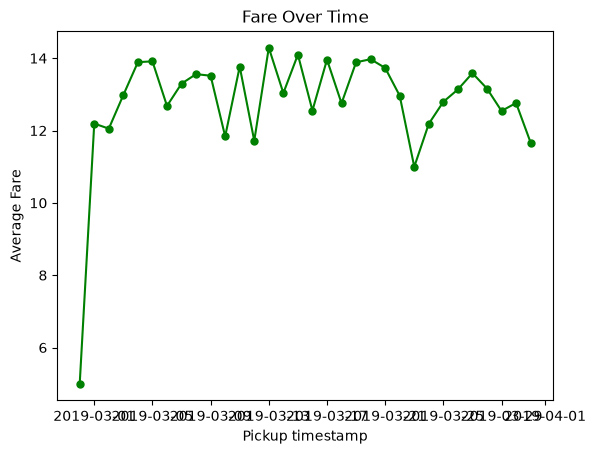

In [31]:
df["pickup"] = pd.to_datetime(df["pickup"])
df["pickupdate"]=df["pickup"].dt.date
fare_over_time = df.groupby("pickupdate")["fare"].mean()
plt.plot(fare_over_time.index, fare_over_time.values, color="green",marker="o",markersize=5)
plt.title("Fare Over Time")
plt.xlabel("Pickup timestamp")
plt.ylabel("Average Fare")
plt.show()

<b><span style="color:green">The pickup column is converted into datetime format, and the date is extracted into a new column named pickupdate. The data is grouped by pickup date, and the average fare is calculated for each day using groupby() and mean().</span><b>

<b><span style="color:green">The line graph shows how the average taxi fare changes over time. The pickup date is displayed on the x-axis, and the average fare is displayed on the y-axis.The data shows a sharp increase in the average taxi fare during the initial days. After this rise, the average fare fluctuates slightly from day to day, showing small increases and decreases.
</span></b>

<b>★ Bar Chart  </b>

<b>Create a bar chart to show the total fare for each pickup_borough. Group the data 
by pickup_borough and sum the fare for each group. </b>

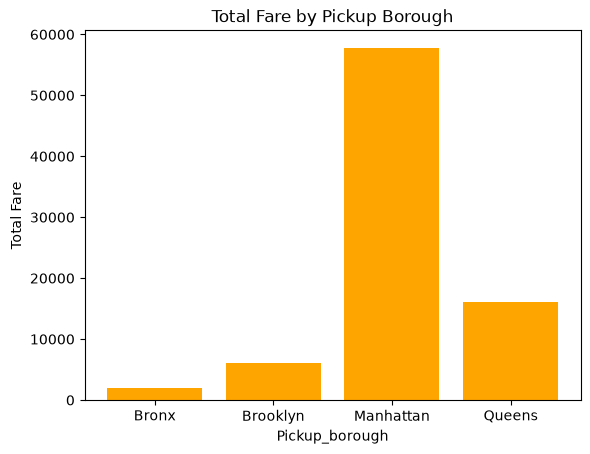

In [34]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()
plt.bar(borough_fare.index,borough_fare.values,color="orange")
plt.xlabel("Pickup_borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")
plt.show()

<b> <span style="color:green">The bar chart compares the total fare by pickup borough.The data is grouped by pickup_borough and total fare values are calculated for each group. Each bar represents a pickup_borough, allowing easy comparison of total fares across different boroughs.</span></b>

<b> <span style="color:green">Here Manhattan has the highest total fare and the Bronx has the lowest.This indicates that taxis picked up in Manhattan generated the most fare revenue, whereas taxis picked up in the Bronx generated the least among the pickup_boroughs.</span> </b>

<b>★ Pie Chart </b>

<b>Plot a pie chart showing the distribution of trips based on the payment method (credit 
card, cash, etc.). Each slice should represent the count of trips for a specific payment 
method.</b> 

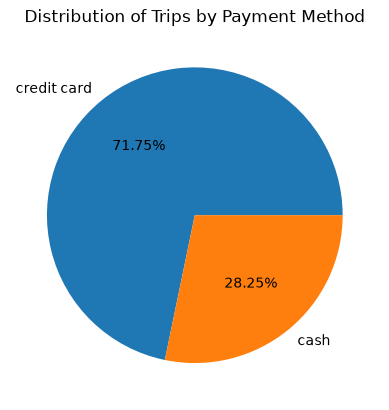

In [36]:
payment_count = df["payment"].value_counts()
plt.pie(payment_count.values,labels=payment_count.index,autopct='%1.2f%%')
plt.title("Distribution of Trips by Payment Method")
plt.show()

<b> <span style="color:green">The pie chart shows the distribution of taxi trips by payment method.The value_counts() function counts the number of trips for each payment method.</span></b>

<b> <span style="color:green">Here 71.75% of trips were paid by credit card, while 28.25% were paid in cash. This indicates that credit card was the most commonly used payment method.</span></b>

<b>★ Histogram</b>

<b>Create a histogram to visualize the distribution of distance. Customize the number of 
bins for better granularity and ensure the plot is easy to interpret.</b>

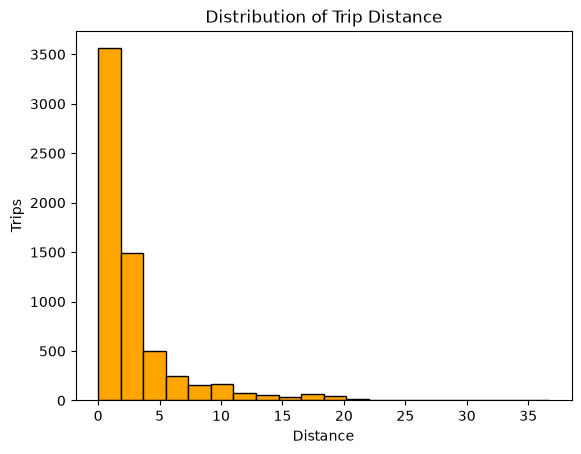

In [6]:
plt.hist(df["distance"],bins=20,edgecolor="black",color="orange")
plt.xlabel("Distance")
plt.ylabel("Trips")
plt.title("Distribution of Trip Distance")
plt.show()

<span style="color:green"><b>The histogram displays the distribution of taxi trip distances.The distance column is plotted using 20 bins.The x-axis represents trip distance, while the y-axis represents the number of trips.</span></b>

<span style="color:green"><b>Here most trips cover shorter distances. The number of trips decreases as the distance increases, indicating that the distribution is concentrated around shorter trips, with fewer trips covering longer distances.</span></b>

<b>★ Box Plot  </b>

<b>Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. 
Use pickup_borough as the categorical axis and tip as the numeric axis.</b>

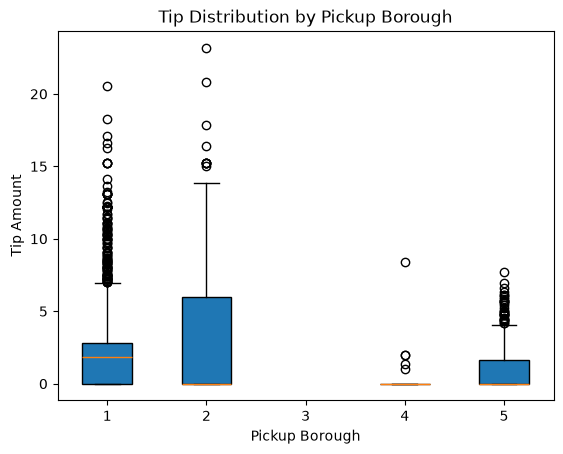

In [26]:
boroughs = df["pickup_borough"].unique()
tips = [df[df["pickup_borough"] == borough]["tip"] for borough in boroughs]
plt.boxplot(tips,label=boroughs,patch_artist=True)
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Tip Distribution by Pickup Borough")
plt.show()

<span style="color:green"><b>The box plot shows the distribution of tip amounts for different pickup boroughs.The circles above the boxes represent outliers, which indicate trips with unusually high tips.Here most tips are low.</b></span>

### <b> <span style="color:purple">Visualizations using Seaborn:</span> </b>

<b>★ Count Plot  </b>

<b>Create a count plot to visualize the number of trips in each pickup_borough. The 
x-axis should represent the boroughs, and the y-axis should show the count of trips.</b>

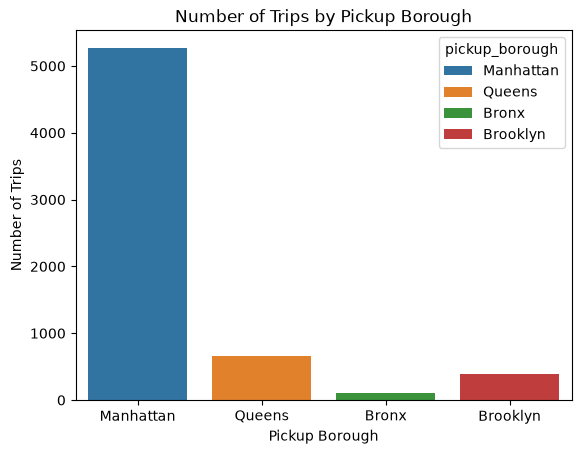

In [12]:
sns.countplot(data=df, x="pickup_borough",hue="pickup_borough")
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.show()

<span style="color:green"><b>The count plot shows the number of trips in each pickup borough.Here Manhattan has the highest number of taxi pickups in the dataset,while the Bronx has the lowest number of taxi pickups.</span></b>

<b>★ Scatter Plot  </b>

<b>Plot a scatter plot to show the relationship between distance and fare. Use 
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the 
points based on the pickup_borough to differentiate the trips by their respective 
boroughs. </b>

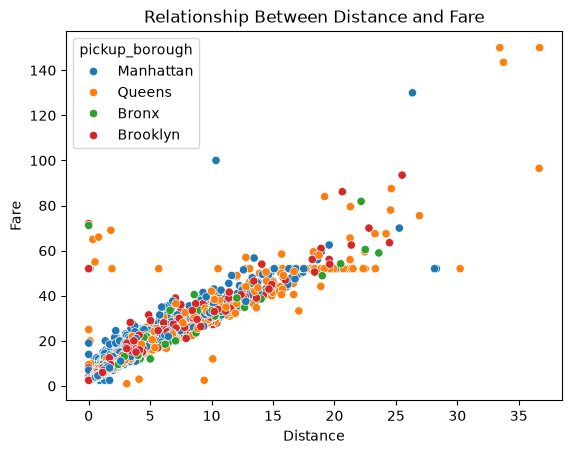

In [14]:
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough")
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.show()

<span style="color:green"><b>The scatter plot shows the relationship between trip distance and fare.From the graph, we can see that as the distance increases, the fare also increases. Different colors represent trips from different pickup boroughs.Most trips are concentrated within shorter distances and lower fares.</span></b>

<b>★ Heatmap  </b>

<b>Plot a heatmap to visualize the correlation between numerical variables such as 
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the 
relationships. </b>

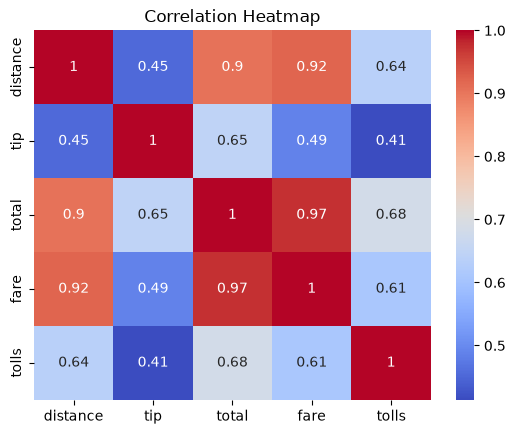

In [15]:
correlation=df[["distance","tip","total","fare","tolls"]].corr()
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

<span style="color:green"><b>The heatmap shows the relationships between distance, tip, total, fare, and tolls.Here the heatmap shows that distance and fare are strongly related, while the total amount is closely associated with the fare.</span></b>

<b>★ Pair Plot </b>

<b>Create a pair plot to visualize the pairwise relationships between distance, fare, tip, 
and total. Color the data points according to the pickup_zone method to compare 
how different zones affect these variables.</b> 

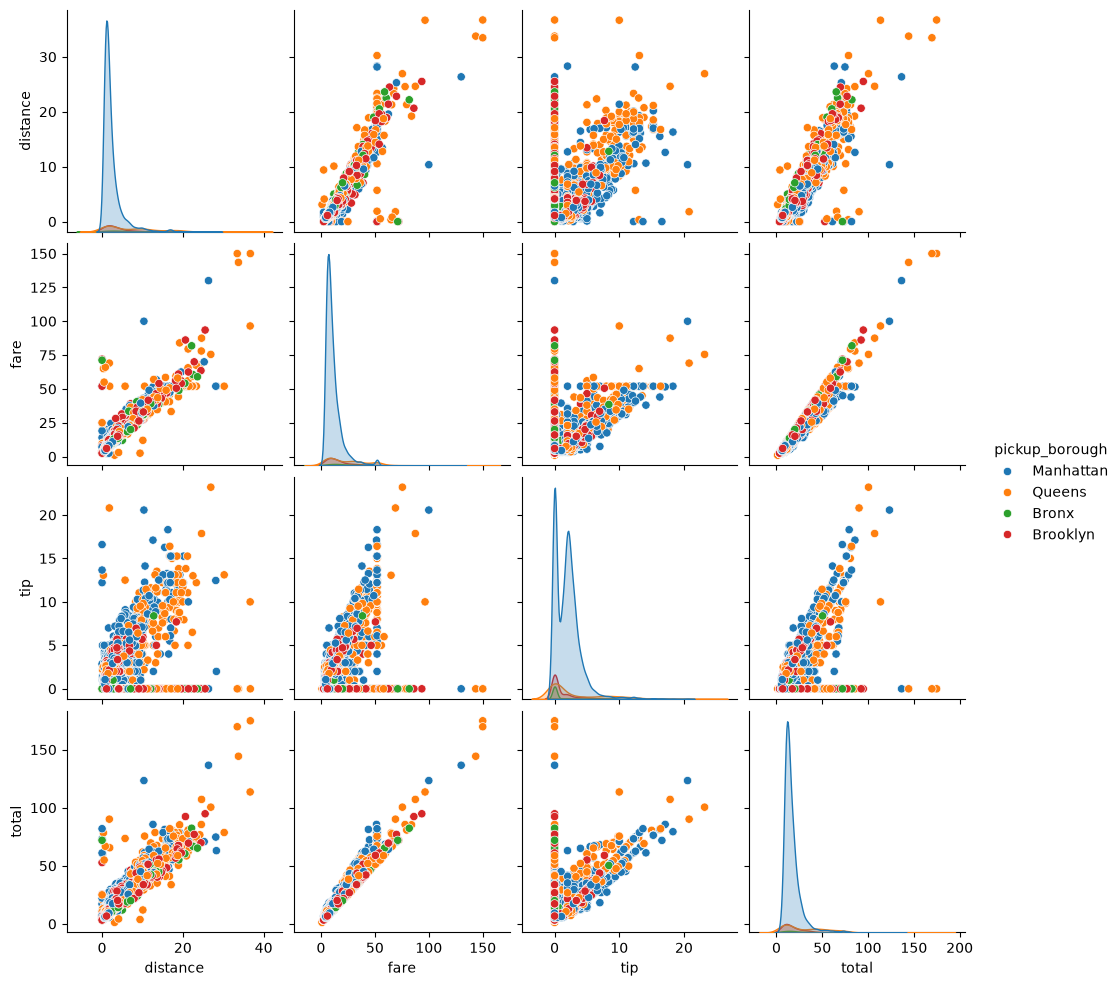

In [18]:
df=sns.load_dataset("taxis")
sns.pairplot(data=df,vars=["distance", "fare", "tip", "total"],hue="pickup_borough")
plt.show()

<span style="color:green"><b>The pair plot displays the relationships between distance, fare, tip, and total.Different colors represent trips from different pickup boroughs.Here as distance increases, both fare and total generally increase.Fare and total also show a strong relationship that is the fare contributes to the total trip amount.</span></b>

<b>★ Violin Plot  </b>

<b>Plot a violin plot to show the distribution of fare for each payment method. Use the 
payment method as the categorical axis and fare as the numeric axis to visualize its 
distribution.</b>

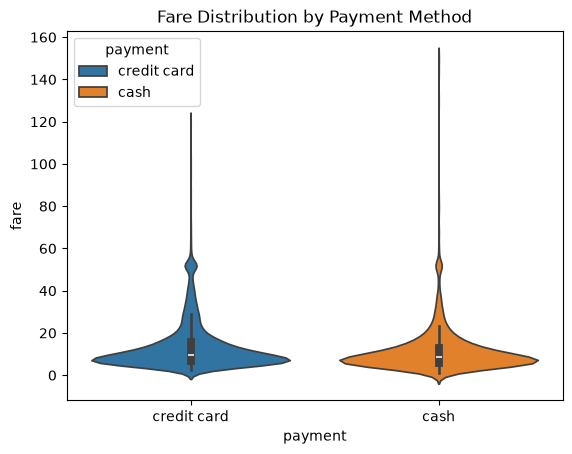

In [19]:
sns.violinplot(data=df,x="payment",y="fare",hue="payment")
plt.title("Fare Distribution by Payment Method")
plt.show()

<span style="color:green"><b>The violin plot compares the distribution of taxi fares for each payment method.Here most fares are low for both payment methods.The wider parts of the violins show where most fares are concentrated, while the narrow upper parts show that higher fares are less common.most trips have low fares, whether passengers pay by credit card or cash.</span></b>